In [1]:
# ==========================================
# Cell 1
# Import Library
# ==========================================

import os
import json
import random
from pathlib import Path
from datetime import datetime

import cv2
import numpy as np
import pandas as pd

from tqdm import tqdm

import matplotlib.pyplot as plt

from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", None)

In [2]:
# ==========================================
# Cell 2
# Configuration
# ==========================================

CURRENT_DIR = Path.cwd().resolve()

PROJECT_DIR = CURRENT_DIR

# ------------------------------------------
# Auto Detect Project Root
# ต้องมีทั้ง output และ dataset
# ------------------------------------------

while True:

    has_output = (PROJECT_DIR / "output").exists()
    has_dataset = (PROJECT_DIR / "dataset").exists()

    if has_output and has_dataset:
        break

    if PROJECT_DIR.parent == PROJECT_DIR:
        raise FileNotFoundError(
            "Cannot find project root."
        )

    PROJECT_DIR = PROJECT_DIR.parent

# ------------------------------------------
# Main Folder
# ------------------------------------------

OUTPUT_DIR = PROJECT_DIR / "output"

VIDEO_DIR = OUTPUT_DIR

DATASET_DIR = OUTPUT_DIR / "dataset"

VERIFY_DIR = DATASET_DIR / "verify"

EXPORT_DIR = DATASET_DIR / "export"

LOG_DIR = DATASET_DIR / "logs"

VOCAB_DIR = DATASET_DIR / "vocabulary"

for folder in [

    DATASET_DIR,

    VERIFY_DIR,

    EXPORT_DIR,

    LOG_DIR,

    VOCAB_DIR

]:

    folder.mkdir(
        parents=True,
        exist_ok=True
    )

# ------------------------------------------
# Files
# ------------------------------------------

LABEL_FILE = DATASET_DIR / "labels.csv"

MASTER_FILE = DATASET_DIR / "dataset_master.csv"

SPLIT_FILE = DATASET_DIR / "split.csv"

VOCAB_FILE = DATASET_DIR / "vocabulary.csv"

STAT_FILE = DATASET_DIR / "statistics.json"

REPORT_FILE = DATASET_DIR / "report.txt"

# ------------------------------------------
# Dataset
# ------------------------------------------

DATASET_VERSION = datetime.now().strftime("v%Y%m%d")

TRAIN_RATIO = 0.80

VAL_RATIO = 0.10

TEST_RATIO = 0.10

RANDOM_SEED = 42

random.seed(RANDOM_SEED)

np.random.seed(RANDOM_SEED)

DEFAULT_SPEAKER = "UNKNOWN"

DEFAULT_LABEL = ""

VIDEO_PATTERN = "video*"

VIDEO_FOLDERS = sorted(

    [

        p

        for p in VIDEO_DIR.glob(VIDEO_PATTERN)

        if p.is_dir()

    ]

)

print("=" * 70)
print("Phase 7 Configuration")
print("=" * 70)

print("Current Dir :", CURRENT_DIR)
print("Project Dir :", PROJECT_DIR)
print("Output Dir  :", OUTPUT_DIR)

print()

print(f"Videos Found : {len(VIDEO_FOLDERS)}")

for video in VIDEO_FOLDERS:

    print(" -", video.name)

print("=" * 70)

if len(VIDEO_FOLDERS) == 0:

    raise RuntimeError(

        "No video folders found."

    )

Phase 7 Configuration
Current Dir : C:\LipReadingSSL\notebooks
Project Dir : C:\LipReadingSSL
Output Dir  : C:\LipReadingSSL\output

Videos Found : 2
 - video001
 - video002


In [3]:
# ==========================================
# Cell 3
# Scan Phase 6 Output
# ==========================================

rows = []

for video in VIDEO_FOLDERS:

    clip_npy_dir = video / "clip_npy"

    clip_img_dir = video / "clips"

    metadata_csv = video / "clip_metadata.csv"

    quality_csv = video / "quality_report.csv"

    mouth_csv = video / "mouth_metadata.csv"

    npy_files = sorted(

        clip_npy_dir.glob("*.npy")

    )

    jpg_files = sorted(

        clip_img_dir.glob("*.jpg")

    )

    rows.append({

        "video_id": video.name,

        "video_path": video,

        "clip_npy_dir": clip_npy_dir,

        "clip_img_dir": clip_img_dir,

        "metadata_csv": metadata_csv,

        "quality_csv": quality_csv,

        "mouth_csv": mouth_csv,

        "num_npy": len(npy_files),

        "num_jpg": len(jpg_files),

        "metadata_exists": metadata_csv.exists(),

        "quality_exists": quality_csv.exists(),

        "mouth_exists": mouth_csv.exists()

    })

video_df = pd.DataFrame(rows)

display(video_df)

print()

print("=" * 70)

print("Total Videos :", len(video_df))

print("Total Clips  :", video_df["num_npy"].sum())

print("=" * 70)

,video_id,video_path,clip_npy_dir,clip_img_dir,metadata_csv,quality_csv,mouth_csv,num_npy,num_jpg,metadata_exists,quality_exists,mouth_exists
0,video001,C:\LipReadingSSL\output\video001,C:\LipReadingSSL\output\video001\clip_npy,C:\LipReadingSSL\output\video001\clips,C:\LipReadingSSL\output\video001\clip_metadata.csv,C:\LipReadingSSL\output\video001\quality_report.csv,C:\LipReadingSSL\output\video001\mouth_metadata.csv,42993,0,True,True,True
1,video002,C:\LipReadingSSL\output\video002,C:\LipReadingSSL\output\video002\clip_npy,C:\LipReadingSSL\output\video002\clips,C:\LipReadingSSL\output\video002\clip_metadata.csv,C:\LipReadingSSL\output\video002\quality_report.csv,C:\LipReadingSSL\output\video002\mouth_metadata.csv,38860,0,True,True,True



Total Videos : 2
Total Clips  : 81853


In [4]:
# ==========================================
# Cell 4
# Build Dataset Index
# ==========================================

clip_rows = []

print("=" * 80)
print("Building Dataset Index")
print("=" * 80)

for _, video in video_df.iterrows():

    video_id = video["video_id"]

    metadata_csv = Path(video["metadata_csv"])

    if not metadata_csv.exists():

        print(f"[Skip] {video_id} : clip_metadata.csv not found")

        continue

    meta = pd.read_csv(metadata_csv)

    required = [

        "clip_id",

        "jpg_folder",

        "npy_path",

        "start_frame",

        "end_frame",

        "num_frames"

    ]

    missing = [

        c

        for c in required

        if c not in meta.columns

    ]

    if len(missing):

        raise ValueError(

            f"{video_id} missing columns : {missing}"

        )

    print(

        f"{video_id:12s} : {len(meta):6d} clips"

    )

    for _, r in meta.iterrows():

        clip_path = Path(r["npy_path"])

        jpg_folder = Path(r["jpg_folder"])

        clip_rows.append({

            # -----------------------
            # Identity
            # -----------------------

            "video_id": video_id,

            "clip_id": str(r["clip_id"]),

            # -----------------------
            # Files
            # -----------------------

            "clip_path": str(clip_path),

            "frame_folder": str(jpg_folder),

            # -----------------------
            # Clip Info
            # -----------------------

            "start_frame": int(r["start_frame"]),

            "end_frame": int(r["end_frame"]),

            "num_frames": int(r["num_frames"]),

            "clip_length":

                float(

                    r.get(

                        "clip_length",

                        np.nan

                    )

                ),

            "stride":

                int(

                    r.get(

                        "stride",

                        1

                    )

                ),

            # -----------------------
            # Label
            # -----------------------

            "speaker_id": DEFAULT_SPEAKER,

            "sentence_id": "",

            "transcript": "",

            "normalized_text": "",

            "language": "th",

            "verified": False

        })

clip_df = pd.DataFrame(clip_rows)

# --------------------------------------------
# Verify
# --------------------------------------------

clip_df["clip_exists"] = clip_df["clip_path"].apply(

    lambda x: Path(x).exists()

)

clip_df["frame_exists"] = clip_df["frame_folder"].apply(

    lambda x: Path(x).exists()

)

print()

print("=" * 80)

print(f"Total Clips        : {len(clip_df)}")

print(

    f"Missing NPY Files  : {(~clip_df['clip_exists']).sum()}"

)

print(

    f"Missing JPG Folder : {(~clip_df['frame_exists']).sum()}"

)

print("=" * 80)

display(clip_df.head())

Building Dataset Index
video001     :  42993 clips
video002     :  38860 clips

Total Clips        : 81853
Missing NPY Files  : 81853
Missing JPG Folder : 81853


,video_id,clip_id,clip_path,frame_folder,start_frame,end_frame,num_frames,clip_length,stride,speaker_id,sentence_id,transcript,normalized_text,language,verified,clip_exists,frame_exists
0,video001,clip_000001,video001\clip_npy\clip_000001.npy,video001\clips\clip_000001,0,25,29,29.0,1,UNKNOWN,,,,th,False,False,False
1,video001,clip_000002,video001\clip_npy\clip_000002.npy,video001\clips\clip_000002,0,26,29,29.0,1,UNKNOWN,,,,th,False,False,False
2,video001,clip_000003,video001\clip_npy\clip_000003.npy,video001\clips\clip_000003,1,27,29,29.0,1,UNKNOWN,,,,th,False,False,False
3,video001,clip_000004,video001\clip_npy\clip_000004.npy,video001\clips\clip_000004,2,28,29,29.0,1,UNKNOWN,,,,th,False,False,False
4,video001,clip_000005,video001\clip_npy\clip_000005.npy,video001\clips\clip_000005,3,29,29,29.0,1,UNKNOWN,,,,th,False,False,False


In [5]:
# ==========================================
# Cell 5
# Dataset Verification
# ==========================================

print("=" * 80)
print("Dataset Verification")
print("=" * 80)

duplicate = clip_df.duplicated(

    subset=[

        "video_id",

        "clip_id"

    ]

).sum()

print(

    "Duplicate Clips :",

    duplicate

)

print()

summary = (

    clip_df

    .groupby("video_id")

    .agg(

        clips=("clip_id", "count"),

        avg_frames=("num_frames", "mean"),

        min_frames=("num_frames", "min"),

        max_frames=("num_frames", "max")

    )

)

display(summary)

print()

print("=" * 80)

if duplicate == 0:

    print("Verification Passed")

else:

    print("Duplicate Found")

Dataset Verification
Duplicate Clips : 0



,clips,avg_frames,min_frames,max_frames
video_id,,,,
video001,42993,29.0,29,29
video002,38860,29.0,29,29



Verification Passed


In [6]:
# ==========================================
# Cell 6
# Create Label Template
# ==========================================

if LABEL_FILE.exists():

    labels_df = pd.read_csv(

        LABEL_FILE,

        encoding="utf-8-sig"

    )

    print("Loaded labels.csv")

else:

    labels_df = clip_df[

        [

            "video_id",

            "clip_id"

        ]

    ].copy()

    labels_df["speaker_id"] = DEFAULT_SPEAKER

    labels_df["sentence_id"] = ""

    labels_df["transcript"] = ""

    labels_df["normalized_text"] = ""

    labels_df["language"] = "th"

    labels_df["verified"] = False

    labels_df["created_at"] = datetime.now().strftime(

        "%Y-%m-%d %H:%M:%S"

    )

    labels_df.to_csv(

        LABEL_FILE,

        index=False,

        encoding="utf-8-sig"

    )

    print("Created labels.csv")

# ------------------------------------------
# Keep Label File in Sync
# ------------------------------------------

current = set(

    zip(

        labels_df.video_id,

        labels_df.clip_id

    )

)

new_rows = []

for _, r in clip_df.iterrows():

    key = (

        r.video_id,

        r.clip_id

    )

    if key not in current:

        new_rows.append({

            "video_id": r.video_id,

            "clip_id": r.clip_id,

            "speaker_id": DEFAULT_SPEAKER,

            "sentence_id": "",

            "transcript": "",

            "normalized_text": "",

            "language": "th",

            "verified": False,

            "created_at":

                datetime.now().strftime(

                    "%Y-%m-%d %H:%M:%S"

                )

        })

if len(new_rows):

    labels_df = pd.concat(

        [

            labels_df,

            pd.DataFrame(new_rows)

        ],

        ignore_index=True

    )

    labels_df.to_csv(

        LABEL_FILE,

        index=False,

        encoding="utf-8-sig"

    )

print()

print(

    f"Total Labels : {len(labels_df)}"

)

display(labels_df.head())

Loaded labels.csv

Total Labels : 81853


,video_id,clip_id,speaker_id,sentence_id,transcript,normalized_text,language,verified
0,video001,clip_000001,UNKNOWN,NaN,NaN,NaN,th,False
1,video001,clip_000002,UNKNOWN,NaN,NaN,NaN,th,False
2,video001,clip_000003,UNKNOWN,NaN,NaN,NaN,th,False
3,video001,clip_000004,UNKNOWN,NaN,NaN,NaN,th,False
4,video001,clip_000005,UNKNOWN,NaN,NaN,NaN,th,False


In [7]:
# ==========================================
# Cell 7
# Merge Clip Metadata + Labels
# ==========================================

print("=" * 80)
print("Merge Labels")
print("=" * 80)

# ------------------------------------------
# Duplicate Check
# ------------------------------------------

dup = labels_df.duplicated(

    subset=[

        "video_id",

        "clip_id"

    ]

).sum()

if dup:

    raise ValueError(

        f"labels.csv has {dup} duplicated clips"

    )

# ------------------------------------------
# Merge
# ------------------------------------------

dataset_df = clip_df.merge(

    labels_df,

    on=[

        "video_id",

        "clip_id"

    ],

    how="left",

    validate="one_to_one",

    suffixes=(

        "",

        "_label"

    )

)

# ------------------------------------------
# Replace Label Columns
# ------------------------------------------

label_columns = [

    "speaker_id",

    "sentence_id",

    "transcript",

    "normalized_text",

    "language",

    "verified"

]

for col in label_columns:

    new_col = f"{col}_label"

    if new_col in dataset_df.columns:

        dataset_df[col] = dataset_df[new_col]

        dataset_df.drop(

            columns=new_col,

            inplace=True

        )

print()

print("Dataset Size :", len(dataset_df))

display(dataset_df.head())

Merge Labels

Dataset Size : 81853


,video_id,clip_id,clip_path,frame_folder,start_frame,end_frame,num_frames,clip_length,stride,speaker_id,sentence_id,transcript,normalized_text,language,verified,clip_exists,frame_exists
0,video001,clip_000001,video001\clip_npy\clip_000001.npy,video001\clips\clip_000001,0,25,29,29.0,1,UNKNOWN,NaN,NaN,NaN,th,False,False,False
1,video001,clip_000002,video001\clip_npy\clip_000002.npy,video001\clips\clip_000002,0,26,29,29.0,1,UNKNOWN,NaN,NaN,NaN,th,False,False,False
2,video001,clip_000003,video001\clip_npy\clip_000003.npy,video001\clips\clip_000003,1,27,29,29.0,1,UNKNOWN,NaN,NaN,NaN,th,False,False,False
3,video001,clip_000004,video001\clip_npy\clip_000004.npy,video001\clips\clip_000004,2,28,29,29.0,1,UNKNOWN,NaN,NaN,NaN,th,False,False,False
4,video001,clip_000005,video001\clip_npy\clip_000005.npy,video001\clips\clip_000005,3,29,29,29.0,1,UNKNOWN,NaN,NaN,NaN,th,False,False,False


In [8]:
# ==========================================
# Cell 8
# Dataset Validation
# ==========================================

print("=" * 80)
print("Dataset Validation")
print("=" * 80)

dataset_df["clip_exists"] = dataset_df["clip_path"].apply(

    lambda x: Path(x).exists()

)

dataset_df["frame_exists"] = dataset_df["frame_folder"].apply(

    lambda x: Path(x).exists()

)

dataset_df["has_transcript"] = (

    dataset_df["transcript"]

    .fillna("")

    .str.strip()

    != ""

)

report = {

    "total_clips":

        len(dataset_df),

    "missing_clip":

        int(

            (~dataset_df["clip_exists"]).sum()

        ),

    "missing_frames":

        int(

            (~dataset_df["frame_exists"]).sum()

        ),

    "labeled":

        int(

            dataset_df["has_transcript"].sum()

        ),

    "unlabeled":

        int(

            (~dataset_df["has_transcript"]).sum()

        )

}

for k, v in report.items():

    print(f"{k:20s}: {v}")

display(

    dataset_df.head()

)

Dataset Validation
total_clips         : 81853
missing_clip        : 81853
missing_frames      : 81853
labeled             : 0
unlabeled           : 81853


,video_id,clip_id,clip_path,frame_folder,start_frame,end_frame,num_frames,clip_length,stride,speaker_id,sentence_id,transcript,normalized_text,language,verified,clip_exists,frame_exists,has_transcript
0,video001,clip_000001,video001\clip_npy\clip_000001.npy,video001\clips\clip_000001,0,25,29,29.0,1,UNKNOWN,NaN,NaN,NaN,th,False,False,False,False
1,video001,clip_000002,video001\clip_npy\clip_000002.npy,video001\clips\clip_000002,0,26,29,29.0,1,UNKNOWN,NaN,NaN,NaN,th,False,False,False,False
2,video001,clip_000003,video001\clip_npy\clip_000003.npy,video001\clips\clip_000003,1,27,29,29.0,1,UNKNOWN,NaN,NaN,NaN,th,False,False,False,False
3,video001,clip_000004,video001\clip_npy\clip_000004.npy,video001\clips\clip_000004,2,28,29,29.0,1,UNKNOWN,NaN,NaN,NaN,th,False,False,False,False
4,video001,clip_000005,video001\clip_npy\clip_000005.npy,video001\clips\clip_000005,3,29,29,29.0,1,UNKNOWN,NaN,NaN,NaN,th,False,False,False,False


In [9]:
# ==========================================
# Cell 9
# Save Dataset Master
# ==========================================

print("=" * 80)
print("Saving Dataset")
print("=" * 80)

dataset_df.insert(

    0,

    "dataset_id",

    np.arange(

        1,

        len(dataset_df)+1

    )

)

dataset_df = dataset_df.sort_values(

    [

        "video_id",

        "clip_id"

    ]

).reset_index(

    drop=True

)

dataset_df.to_csv(

    MASTER_FILE,

    index=False,

    encoding="utf-8-sig"

)

print()

print("Saved")

print(MASTER_FILE)

print()

print(dataset_df.shape)

display(dataset_df.head())

Saving Dataset

Saved
C:\LipReadingSSL\output\dataset\dataset_master.csv

(81853, 19)


,dataset_id,video_id,clip_id,clip_path,frame_folder,start_frame,end_frame,num_frames,clip_length,stride,speaker_id,sentence_id,transcript,normalized_text,language,verified,clip_exists,frame_exists,has_transcript
0,1,video001,clip_000001,video001\clip_npy\clip_000001.npy,video001\clips\clip_000001,0,25,29,29.0,1,UNKNOWN,NaN,NaN,NaN,th,False,False,False,False
1,2,video001,clip_000002,video001\clip_npy\clip_000002.npy,video001\clips\clip_000002,0,26,29,29.0,1,UNKNOWN,NaN,NaN,NaN,th,False,False,False,False
2,3,video001,clip_000003,video001\clip_npy\clip_000003.npy,video001\clips\clip_000003,1,27,29,29.0,1,UNKNOWN,NaN,NaN,NaN,th,False,False,False,False
3,4,video001,clip_000004,video001\clip_npy\clip_000004.npy,video001\clips\clip_000004,2,28,29,29.0,1,UNKNOWN,NaN,NaN,NaN,th,False,False,False,False
4,5,video001,clip_000005,video001\clip_npy\clip_000005.npy,video001\clips\clip_000005,3,29,29,29.0,1,UNKNOWN,NaN,NaN,NaN,th,False,False,False,False


In [10]:
# ==========================================
# Cell 10
# Train / Validation / Test Split
# ==========================================

print("=" * 80)
print("Dataset Split")
print("=" * 80)

videos = sorted(dataset_df.video_id.unique())

n_video = len(videos)

print(f"Videos : {n_video}")

random.seed(RANDOM_SEED)

random.shuffle(videos)

# -------------------------------------------------
# Smart Split
# -------------------------------------------------

if n_video == 1:

    train_video = videos
    val_video = []
    test_video = []

elif n_video == 2:

    train_video = [videos[0]]
    val_video = []
    test_video = [videos[1]]

else:

    n_train = max(1, round(n_video * TRAIN_RATIO))
    n_val = max(1, round(n_video * VAL_RATIO))

    if n_train + n_val >= n_video:

        n_val = 1
        n_train = n_video - 2

    train_video = videos[:n_train]

    val_video = videos[n_train:n_train+n_val]

    test_video = videos[n_train+n_val:]

dataset_df["split"] = "test"

dataset_df.loc[
    dataset_df.video_id.isin(train_video),
    "split"
] = "train"

dataset_df.loc[
    dataset_df.video_id.isin(val_video),
    "split"
] = "val"

print()

print(dataset_df["split"].value_counts())

split_df = dataset_df[
    [
        "dataset_id",
        "video_id",
        "clip_id",
        "split"
    ]
]

split_df.to_csv(
    SPLIT_FILE,
    index=False,
    encoding="utf-8-sig"
)

display(split_df.head())

Dataset Split
Videos : 2

split
test     42993
train    38860
Name: count, dtype: int64


,dataset_id,video_id,clip_id,split
0,1,video001,clip_000001,test
1,2,video001,clip_000002,test
2,3,video001,clip_000003,test
3,4,video001,clip_000004,test
4,5,video001,clip_000005,test


In [11]:
# ==========================================
# Cell 11
# Build Thai Vocabulary
# ==========================================

print("=" * 80)
print("Building Vocabulary")
print("=" * 80)

try:

    from pythainlp.tokenize import word_tokenize

    USE_THAI_NLP = True

except:

    USE_THAI_NLP = False

texts = (

    dataset_df["normalized_text"]

    .fillna("")

    .astype(str)

    .str.strip()

)

texts = texts[texts != ""]

# ====================================================
# Character Vocabulary
# ====================================================

chars = set()

for sentence in texts:

    for ch in sentence:

        if ch.strip():

            chars.add(ch)

chars = sorted(chars)

char_df = pd.DataFrame({

    "char_id": range(len(chars)),

    "character": chars

})

char_file = VOCAB_DIR / "character_vocab.csv"

char_df.to_csv(

    char_file,

    index=False,

    encoding="utf-8-sig"

)

# ====================================================
# Word Vocabulary
# ====================================================

words = set()

for sentence in texts:

    if USE_THAI_NLP:

        tokens = word_tokenize(

            sentence,

            engine="newmm"

        )

    else:

        tokens = sentence.split()

    for token in tokens:

        token = token.strip()

        if token:

            words.add(token)

words = sorted(words)

word_df = pd.DataFrame({

    "word_id": range(len(words)),

    "word": words

})

word_file = VOCAB_DIR / "word_vocab.csv"

word_df.to_csv(

    word_file,

    index=False,

    encoding="utf-8-sig"

)

# ====================================================
# Sentence Database
# ====================================================

sentence_df = pd.DataFrame({

    "sentence_id":

        range(

            1,

            len(texts.unique())+1

        ),

    "sentence":

        sorted(texts.unique())

})

sentence_file = VOCAB_DIR / "sentence_database.csv"

sentence_df.to_csv(

    sentence_file,

    index=False,

    encoding="utf-8-sig"

)

print()

print(f"Characters : {len(char_df)}")

print(f"Words      : {len(word_df)}")

print(f"Sentences  : {len(sentence_df)}")

display(char_df.head())

display(word_df.head())

display(sentence_df.head())

Building Vocabulary

Characters : 0
Words      : 0
Sentences  : 0


,char_id,character


,word_id,word


,sentence_id,sentence


In [12]:
# ==========================================
# Cell 12
# Export Dataset
# ==========================================

print("=" * 80)
print("Export Dataset")
print("=" * 80)

export_columns = [

    "dataset_id",

    "video_id",

    "clip_id",

    "clip_path",

    "frame_folder",

    "start_frame",

    "end_frame",

    "num_frames",

    "speaker_id",

    "sentence_id",

    "transcript",

    "normalized_text",

    "language",

    "verified",

    "split"

]

export_df = dataset_df[export_columns].copy()

# -------------------------------------------------
# Save Full Dataset
# -------------------------------------------------

export_df.to_csv(

    EXPORT_DIR / "dataset.csv",

    index=False,

    encoding="utf-8-sig"

)

# -------------------------------------------------
# Train
# -------------------------------------------------

export_df[
    export_df.split == "train"
].to_csv(

    EXPORT_DIR / "train.csv",

    index=False,

    encoding="utf-8-sig"

)

# -------------------------------------------------
# Validation
# -------------------------------------------------

export_df[
    export_df.split == "val"
].to_csv(

    EXPORT_DIR / "val.csv",

    index=False,

    encoding="utf-8-sig"

)

# -------------------------------------------------
# Test
# -------------------------------------------------

export_df[
    export_df.split == "test"
].to_csv(

    EXPORT_DIR / "test.csv",

    index=False,

    encoding="utf-8-sig"

)

print()

print("Dataset Exported")

print()

print(EXPORT_DIR)

display(export_df.head())

Export Dataset

Dataset Exported

C:\LipReadingSSL\output\dataset\export


,dataset_id,video_id,clip_id,clip_path,frame_folder,start_frame,end_frame,num_frames,speaker_id,sentence_id,transcript,normalized_text,language,verified,split
0,1,video001,clip_000001,video001\clip_npy\clip_000001.npy,video001\clips\clip_000001,0,25,29,UNKNOWN,NaN,NaN,NaN,th,False,test
1,2,video001,clip_000002,video001\clip_npy\clip_000002.npy,video001\clips\clip_000002,0,26,29,UNKNOWN,NaN,NaN,NaN,th,False,test
2,3,video001,clip_000003,video001\clip_npy\clip_000003.npy,video001\clips\clip_000003,1,27,29,UNKNOWN,NaN,NaN,NaN,th,False,test
3,4,video001,clip_000004,video001\clip_npy\clip_000004.npy,video001\clips\clip_000004,2,28,29,UNKNOWN,NaN,NaN,NaN,th,False,test
4,5,video001,clip_000005,video001\clip_npy\clip_000005.npy,video001\clips\clip_000005,3,29,29,UNKNOWN,NaN,NaN,NaN,th,False,test


In [13]:
# ==========================================
# Cell 13
# Dataset Statistics
# ==========================================

print("=" * 80)
print("Dataset Statistics")
print("=" * 80)

statistics = {

    "dataset_version": DATASET_VERSION,

    "created_at": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),

    "total_samples": int(len(dataset_df)),

    "total_videos": int(dataset_df["video_id"].nunique()),

    "total_speakers": int(dataset_df["speaker_id"].nunique()),

    "total_sentences": int(
        dataset_df["normalized_text"]
        .fillna("")
        .replace("", np.nan)
        .dropna()
        .nunique()
    ),

    "train_samples": int(
        (dataset_df["split"] == "train").sum()
    ),

    "val_samples": int(
        (dataset_df["split"] == "val").sum()
    ),

    "test_samples": int(
        (dataset_df["split"] == "test").sum()
    ),

    "character_vocab": int(len(char_df)),

    "word_vocab": int(len(word_df))

}

# ------------------------------------------
# Clip Length Statistics
# ------------------------------------------

frames = pd.to_numeric(
    dataset_df["num_frames"],
    errors="coerce"
).dropna()

if len(frames):

    statistics["min_frames"] = int(frames.min())

    statistics["max_frames"] = int(frames.max())

    statistics["avg_frames"] = round(
        frames.mean(),
        2
    )

    statistics["median_frames"] = int(
        frames.median()
    )

else:

    statistics["min_frames"] = None

    statistics["max_frames"] = None

    statistics["avg_frames"] = None

    statistics["median_frames"] = None

with open(
    STAT_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        statistics,
        f,
        indent=4,
        ensure_ascii=False
    )

display(
    pd.DataFrame(
        statistics.items(),
        columns=[
            "Metric",
            "Value"
        ]
    )
)

Dataset Statistics


C:\Users\User\AppData\Local\Temp\ipykernel_149344\186028063.py:25: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace("", np.nan)


,Metric,Value
0,dataset_version,v20260805
1,created_at,2026-08-05 21:44:11
2,total_samples,81853
3,total_videos,2
4,total_speakers,1
5,total_sentences,0
6,train_samples,38860
7,val_samples,0
8,test_samples,42993
9,character_vocab,0


In [14]:
# ==========================================
# Cell 14
# Dataset Integrity Check
# ==========================================

print("=" * 80)
print("Dataset Integrity Check")
print("=" * 80)

report = {}

report["duplicate_dataset_id"] = int(
    dataset_df.duplicated(
        subset=["dataset_id"]
    ).sum()
)

report["duplicate_clip"] = int(
    dataset_df.duplicated(
        subset=[
            "video_id",
            "clip_id"
        ]
    ).sum()
)

report["missing_npy"] = int(
    (~dataset_df["clip_exists"]).sum()
)

report["missing_frame_folder"] = int(
    (~dataset_df["frame_exists"]).sum()
)

report["missing_transcript"] = int(

    dataset_df["transcript"]

    .fillna("")

    .str.strip()

    .eq("")

    .sum()

)

report["missing_sentence"] = int(

    dataset_df["normalized_text"]

    .fillna("")

    .str.strip()

    .eq("")

    .sum()

)

report["missing_split"] = int(

    dataset_df["split"]

    .isna()

    .sum()

)

report["invalid_num_frames"] = int(

    pd.to_numeric(

        dataset_df["num_frames"],

        errors="coerce"

    )

    .isna()

    .sum()

)

integrity_df = pd.DataFrame(

    report.items(),

    columns=[

        "Check",

        "Count"

    ]

)

display(integrity_df)

if integrity_df["Count"].sum() == 0:

    print()

    print("Dataset Integrity : PASSED")

else:

    print()

    print("Dataset Integrity : WARNING")

Dataset Integrity Check


,Check,Count
0,duplicate_dataset_id,0
1,duplicate_clip,0
2,missing_npy,81853
3,missing_frame_folder,81853
4,missing_transcript,81853
5,missing_sentence,81853
6,missing_split,0
7,invalid_num_frames,0



Dataset Integrity : WARNING


Dataset Visualization


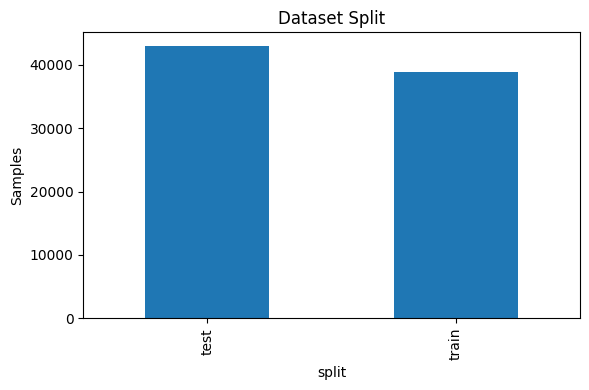

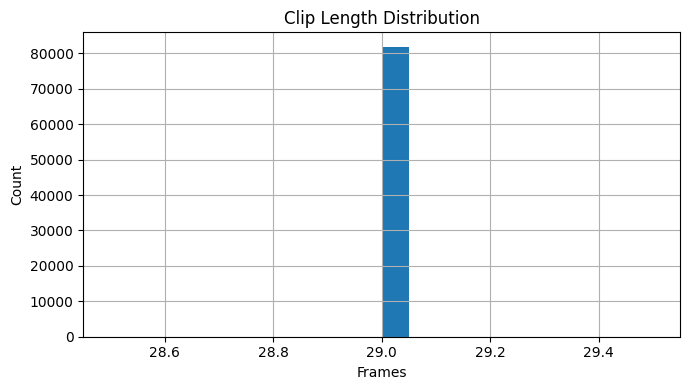

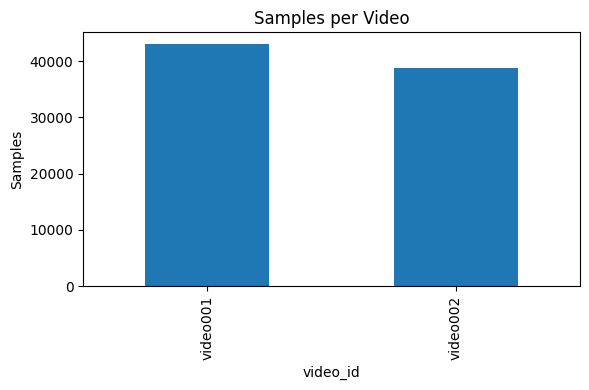

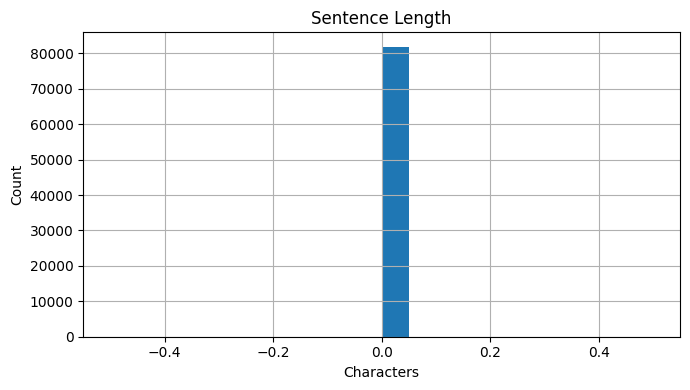


Visualization Complete


In [15]:
# ==========================================
# Cell 15
# Dataset Visualization
# ==========================================

import matplotlib.pyplot as plt

print("=" * 80)
print("Dataset Visualization")
print("=" * 80)

# ------------------------------------------
# Split Distribution
# ------------------------------------------

plt.figure(figsize=(6,4))

dataset_df["split"].value_counts().plot(
    kind="bar"
)

plt.title("Dataset Split")

plt.ylabel("Samples")

plt.tight_layout()

plt.show()

# ------------------------------------------
# Clip Length
# ------------------------------------------

plt.figure(figsize=(7,4))

pd.to_numeric(
    dataset_df["num_frames"],
    errors="coerce"
).dropna().hist(
    bins=20
)

plt.title("Clip Length Distribution")

plt.xlabel("Frames")

plt.ylabel("Count")

plt.tight_layout()

plt.show()

# ------------------------------------------
# Samples per Video
# ------------------------------------------

plt.figure(figsize=(6,4))

dataset_df.groupby(

    "video_id"

).size().plot(

    kind="bar"

)

plt.title("Samples per Video")

plt.ylabel("Samples")

plt.tight_layout()

plt.show()

# ------------------------------------------
# Sentence Length
# ------------------------------------------

sentence_length = (

    dataset_df["normalized_text"]

    .fillna("")

    .astype(str)

    .apply(

        lambda x: len(x)

    )

)

plt.figure(figsize=(7,4))

sentence_length.hist(

    bins=20

)

plt.title("Sentence Length")

plt.xlabel("Characters")

plt.ylabel("Count")

plt.tight_layout()

plt.show()

print()

print("Visualization Complete")

In [16]:
# ==========================================
# Cell 16
# Export Training Configuration
# ==========================================

print("=" * 80)
print("Export Training Configuration")
print("=" * 80)

# --------------------------------------------------
# Safe Clip Length
# --------------------------------------------------

frames = pd.to_numeric(
    dataset_df["num_frames"],
    errors="coerce"
).dropna()

clip_length = int(frames.median()) if len(frames) else None

# --------------------------------------------------
# Training Config
# --------------------------------------------------

training_config = {

    "dataset_version": DATASET_VERSION,

    "language": "th",

    "num_samples": int(len(dataset_df)),

    "num_videos": int(dataset_df["video_id"].nunique()),

    "num_speakers": int(dataset_df["speaker_id"].nunique()),

    "clip_length": clip_length,

    "image_size": IMAGE_SIZE if "IMAGE_SIZE" in globals() else 224,

    "train_csv": str(EXPORT_DIR / "train.csv"),

    "val_csv": str(EXPORT_DIR / "val.csv"),

    "test_csv": str(EXPORT_DIR / "test.csv"),

    "character_vocab": str(char_file),

    "word_vocab": str(word_file),

    "sentence_database": str(sentence_file),

    "dataset_master": str(MASTER_FILE)

}

config_file = EXPORT_DIR / "training_config.json"

with open(
    config_file,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        training_config,
        f,
        indent=4,
        ensure_ascii=False
    )

print(json.dumps(
    training_config,
    indent=4,
    ensure_ascii=False
))

print()
print("Saved :", config_file)

Export Training Configuration
{
    "dataset_version": "v20260805",
    "language": "th",
    "num_samples": 81853,
    "num_videos": 2,
    "num_speakers": 1,
    "clip_length": 29,
    "image_size": 224,
    "train_csv": "C:\\LipReadingSSL\\output\\dataset\\export\\train.csv",
    "val_csv": "C:\\LipReadingSSL\\output\\dataset\\export\\val.csv",
    "test_csv": "C:\\LipReadingSSL\\output\\dataset\\export\\test.csv",
    "character_vocab": "C:\\LipReadingSSL\\output\\dataset\\vocabulary\\character_vocab.csv",
    "word_vocab": "C:\\LipReadingSSL\\output\\dataset\\vocabulary\\word_vocab.csv",
    "sentence_database": "C:\\LipReadingSSL\\output\\dataset\\vocabulary\\sentence_database.csv",
    "dataset_master": "C:\\LipReadingSSL\\output\\dataset\\dataset_master.csv"
}

Saved : C:\LipReadingSSL\output\dataset\export\training_config.json


In [17]:
# ==========================================
# Cell 17
# Generate Dataset Report
# ==========================================

print("=" * 80)
print("Generate Dataset Report")
print("=" * 80)

report = []

report.append("LipReadingSSL Dataset Report")
report.append("=" * 60)
report.append("")

report.append("GENERAL")
report.append("-" * 30)

for k, v in statistics.items():

    report.append(f"{k:25s}: {v}")

report.append("")
report.append("INTEGRITY")
report.append("-" * 30)

for _, row in integrity_df.iterrows():

    report.append(

        f"{row['Check']:25s}: {row['Count']}"

    )

report.append("")
report.append("FILES")
report.append("-" * 30)

report.append(f"Dataset Master : {MASTER_FILE}")
report.append(f"Labels         : {LABEL_FILE}")
report.append(f"Split          : {SPLIT_FILE}")
report.append(f"Character Vocab: {char_file}")
report.append(f"Word Vocab     : {word_file}")
report.append(f"Sentence DB    : {sentence_file}")

REPORT_FILE.write_text(

    "\n".join(report),

    encoding="utf-8"

)

print(REPORT_FILE)

print()

print("\n".join(report[:20]))

Generate Dataset Report
C:\LipReadingSSL\output\dataset\report.txt

LipReadingSSL Dataset Report

GENERAL
------------------------------
dataset_version          : v20260805
created_at               : 2026-08-05 21:44:11
total_samples            : 81853
total_videos             : 2
total_speakers           : 1
total_sentences          : 0
train_samples            : 38860
val_samples              : 0
test_samples             : 42993
character_vocab          : 0
word_vocab               : 0
min_frames               : 29
max_frames               : 29
avg_frames               : 29.0
median_frames            : 29


In [ ]:
# ==========================================
# Cell 18
# Phase 7 Completed
# ==========================================

print("=" * 80)
print("PHASE 7 COMPLETED")
print("=" * 80)

summary = pd.DataFrame({

    "Metric":[

        "Dataset Version",

        "Total Samples",

        "Videos",

        "Speakers",

        "Train",

        "Validation",

        "Test",

        "Character Vocabulary",

        "Word Vocabulary",

        "Sentence Database"

    ],

    "Value":[

        DATASET_VERSION,

        len(dataset_df),

        dataset_df["video_id"].nunique(),

        dataset_df["speaker_id"].nunique(),

        (dataset_df["split"]=="train").sum(),

        (dataset_df["split"]=="val").sum(),

        (dataset_df["split"]=="test").sum(),

        len(char_df),

        len(word_df),

        len(sentence_df)

    ]

})

display(summary)

print()

print("Generated Files")

generated_files = [

    MASTER_FILE,

    LABEL_FILE,

    SPLIT_FILE,

    STAT_FILE,

    REPORT_FILE,

    config_file,

    char_file,

    word_file,

    sentence_file,

    EXPORT_DIR / "dataset.csv",

    EXPORT_DIR / "train.csv",

    EXPORT_DIR / "val.csv",

    EXPORT_DIR / "test.csv"

]

for f in generated_files:

    status = "✓" if Path(f).exists() else "✗"

    print(f"{status} {Path(f).name}")

print()

print("=" * 80)
print("Dataset is READY for Phase 8 (Model Training)")
print("=" * 80)

PHASE 7 COMPLETED


,Metric,Value
0,Dataset Version,v20260805
1,Total Samples,81853
2,Videos,2
3,Speakers,1
4,Train,38860
5,Validation,0
6,Test,42993
7,Character Vocabulary,0
8,Word Vocabulary,0
9,Sentence Database,0



Generated Files
✓ dataset_master.csv
✓ labels.csv
✓ split.csv
✓ statistics.json
✓ report.txt
✓ training_config.json
✓ character_vocab.csv
✓ word_vocab.csv
✓ sentence_database.csv
✓ dataset.csv
✓ train.csv
✓ val.csv
✓ test.csv

Dataset is READY for Phase 8 (Model Training)


: 